# 03 · Static discovery — GG shares + Hasbrouck IS bounds

Three instruments share two common trends, so single-number IS in the trivariate frame is
wrong. We work in the bivariate frame — quoted cross (EURJPY) vs synthetic (EURUSD+USDJPY),
one common trend — where GG and Hasbrouck apply. GG is the primary number; IS is reported as
Cholesky [lo,hi] bounds and shown drifting with frequency (Epps).

In [1]:
%load_ext autoreload
%autoreload 2
import datetime as dt, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from fxpd.config import TRIANGLES, OUTPUTS_DIR, ensure_dirs
from fxpd.data.clean import run_qc
from fxpd.data.processed import get_panel
from fxpd.econo import vecm, discovery as disc
ensure_dirs(); warnings.simplefilter("ignore")
pd.set_option("display.float_format", lambda v: f"{v:.4g}")

## Parameters — tweak these

In [2]:
TRIANGLE = "majors"
START, END       = dt.date(2025, 12, 15), dt.date(2026, 7, 20)
FREQ_CURVE_START, FREQ_CURVE_END = dt.date(2026, 5, 18), dt.date(2026, 6, 19)
FREQS   = ["100ms", "250ms", "1s", "5s"]; PRIMARY = "1s"; LIQUID = (7, 17)
K_PRIMARY = 10
K_TRI     = 5
tri = TRIANGLES[TRIANGLE]
dates    = list(pd.bdate_range(START, END).date)
fc_dates = list(pd.bdate_range(FREQ_CURVE_START, FREQ_CURVE_END).date)
bar1s = pd.Timedelta(PRIMARY).total_seconds()
print(f"{tri} | {len(dates)} business days | primary {PRIMARY} k={K_PRIMARY}, liquid {LIQUID} UTC")

Triangle(name='majors', cross='EURJPY', leg1='EURUSD', leg2='USDJPY') | 156 business days | primary 1s k=10, liquid (7, 17) UTC


## 1 · Data quality & staleness recap

In [3]:
qc = run_qc(list(tri.legs), START, END)
drop = qc[["n_validity","n_crossed","n_spread","n_spike"]].sum(axis=1)
print(f"QC: {len(qc)} instrument-days | drop rate mean {100*(drop/qc.n_input).mean():.3f}% "
      f"max {100*(drop/qc.n_input).max():.3f}% | crossed flags {int(qc.crossed_share_flag.sum())}")

p = get_panel(tri, dates[2], PRIMARY, with_age=True)
fresh = {leg: float((p[f'age_{leg}'] <= bar1s).mean()) for leg in tri.legs}
fresh["synth (both legs)"] = float(((p[f'age_{tri.leg1}']<=bar1s) & (p[f'age_{tri.leg2}']<=bar1s)).mean())
print("\n1s fresh-bar share (one representative day):")
pd.Series(fresh).round(3)

QC: 561 instrument-days | drop rate mean 0.091% max 1.288% | crossed flags 0

1s fresh-bar share (one representative day):


EURJPY              0.581
EURUSD              0.355
USDJPY              0.426
synth (both legs)   0.231
dtype: float64

## 2 · The static discovery table (1 s, liquid hours)

In [4]:
res1s = disc.fit_discovery_windows(tri, dates, PRIMARY, K_PRIMARY, liquid=LIQUID)
agg = disc.aggregate_discovery(res1s)
table = pd.DataFrame({
    "GG median": agg["gg_median"],
    "GG [IQR]": [f"[{r.gg_q25:.3f}, {r.gg_q75:.3f}]" for r in agg.itertuples()],
    "IS [lo, hi]": [f"[{r.is_lo:.3f}, {r.is_hi:.3f}]" for r in agg.itertuples()],
})
print(f"windows: {agg.attrs['n_valid']}/{agg.attrs['n_windows']} valid "
      f"(exclusion {100*agg.attrs['exclusion_rate']:.0f}%, skipped {res1s.attrs['skipped']}) | "
      f"half-life proxy {agg.attrs['half_life_median']:.1f}s / DYNAMIC {agg.attrs['half_life_dyn_median']:.1f}s | "
      f"median resid-corr {agg.attrs['resid_corr_median']:.3f}")
print(f"GG_cross incl. out-of-[0,1] windows (co-primary): median {agg.attrs['gg_inclusive_median']:.3f} "
      f"[IQR {agg.attrs['gg_inclusive_q25']:.3f}, {agg.attrs['gg_inclusive_q75']:.3f}], n={agg.attrs['n_gg_inclusive']}")
table

windows: 151/154 valid (exclusion 2%, skipped 2) | half-life proxy 3.4s / DYNAMIC 8.2s | median resid-corr 0.914
GG_cross incl. out-of-[0,1] windows (co-primary): median 0.654 [IQR 0.584, 0.734], n=154


,GG median,GG [IQR],"IS [lo, hi]"
series,,,
cross,0.6521,"[0.583, 0.727]","[0.073, 0.977]"
synth,0.3479,"[0.273, 0.417]","[0.023, 0.927]"


## 3 · Frequency curve (a result, not a nuisance)

fixed lag k=10 across all frequencies (robustness below)


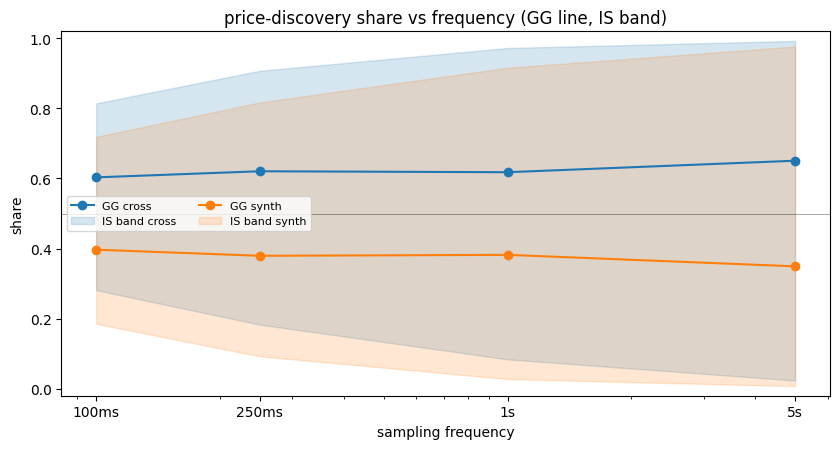

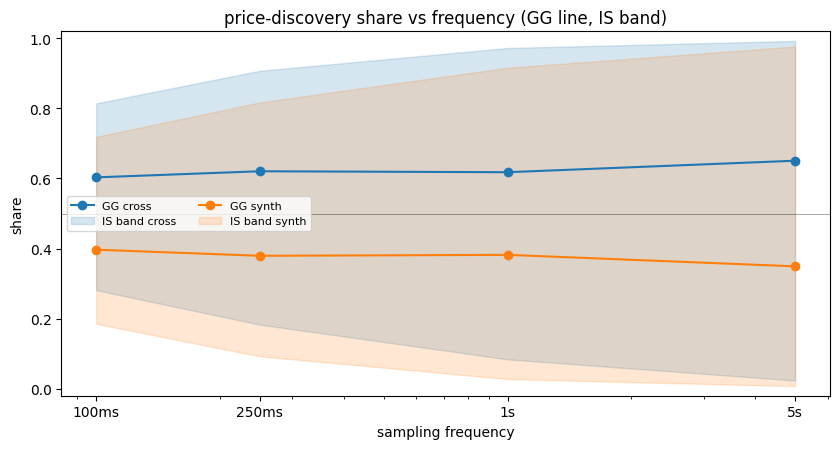

In [5]:
fc = disc.frequency_curve(tri, fc_dates, FREQS, k=K_PRIMARY, liquid=LIQUID)
secs = {"100ms":0.1, "250ms":0.25, "1s":1.0, "5s":5.0}
fc["sec"] = fc["freq"].map(secs)
print(f"fixed lag k={K_PRIMARY} across all frequencies (robustness below)")

fig, ax = plt.subplots(figsize=(8.5, 4.6))
for series, color in [("cross","tab:blue"), ("synth","tab:orange")]:
    d = fc[fc.series==series].sort_values("sec")
    ax.plot(d.sec, d.gg_median, "o-", color=color, label=f"GG {series}")
    ax.fill_between(d.sec, d.is_lo, d.is_hi, color=color, alpha=0.18,
                    label=f"IS band {series}")
ax.set_xscale("log"); ax.axhline(0.5, color="k", lw=0.6, alpha=0.4)
ax.set_xticks(list(secs.values())); ax.set_xticklabels(FREQS)
ax.set_xlabel("sampling frequency"); ax.set_ylabel("share"); ax.set_ylim(-0.02, 1.02)
ax.set_title("price-discovery share vs frequency (GG line, IS band)")
ax.legend(ncol=2, fontsize=8, loc="center left")
fig.tight_layout(); fig.savefig(OUTPUTS_DIR/"03_frequency_curve.png", dpi=130); fig

## 4 · Bound width vs frequency (the Cholesky / Epps story)

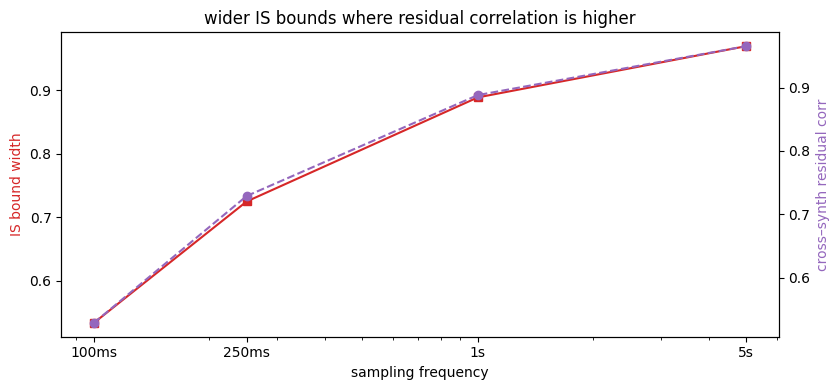

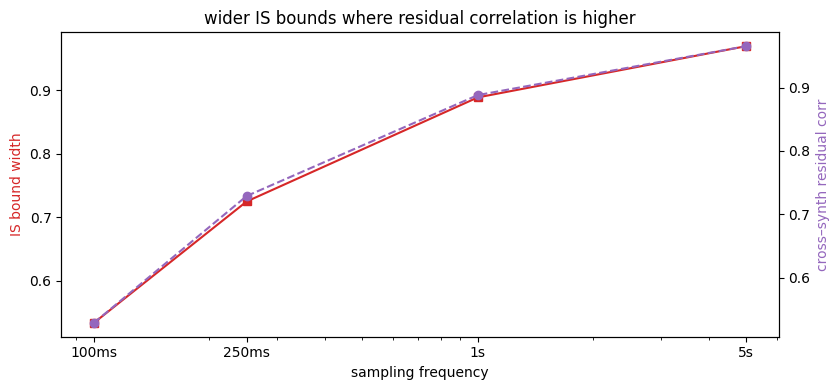

In [6]:
w = fc[fc.series=="cross"].sort_values("sec").copy()
w["width"] = w.is_hi - w.is_lo
fig, ax1 = plt.subplots(figsize=(8.5, 4))
ax1.plot(w.sec, w.width, "s-", color="tab:red", label="IS_cross width (hi−lo)")
ax1.set_xscale("log"); ax1.set_xticks(list(secs.values())); ax1.set_xticklabels(FREQS)
ax1.set_xlabel("sampling frequency"); ax1.set_ylabel("IS bound width", color="tab:red")
ax2 = ax1.twinx()
ax2.plot(w.sec, w.resid_corr, "o--", color="tab:purple", label="resid corr")
ax2.set_ylabel("cross–synth residual corr", color="tab:purple")
ax1.set_title("wider IS bounds where residual correlation is higher")
fig.tight_layout(); fig.savefig(OUTPUTS_DIR/"03_bound_width.png", dpi=130); fig

## 4b · Robustness — the curve is a frequency effect, not a k effect

In [7]:
rob=[]
for kk in [5, 10, 20]:
    fk=disc.frequency_curve(tri, fc_dates, FREQS, k=kk, liquid=LIQUID)
    cc=fk[fk.series=="cross"].set_index("freq")
    for f in FREQS:
        rob.append({"k":kk,"freq":f,"GG_cross":cc.loc[f,"gg_median"],
                    "IS_width":cc.loc[f,"is_hi"]-cc.loc[f,"is_lo"]})
rob=pd.DataFrame(rob).pivot(index="freq",columns="k")[["GG_cross","IS_width"]].loc[FREQS]
rob.round(3)

GG_cross             IS_width            
k           5     10    20       5     10    20
freq                                           
100ms    0.594 0.603 0.617    0.534 0.533 0.532
250ms      0.6 0.621 0.624    0.724 0.725 0.734
1s       0.635 0.618 0.636    0.888 0.888 0.887
5s        0.63 0.651 0.676    0.966 0.969 0.966

## 5 · Attribution aside — which dollar leg adjusts?

In [8]:
res_tri = vecm.fit_windows(tri, dates, PRIMARY, K_TRI, vecm.TRIVARIATE, liquid=LIQUID)
vecm.aggregate_windows(res_tri)[["alpha_median","alpha_q25","alpha_q75","share_|t|>1.96"]]

,alpha_median,alpha_q25,alpha_q75,share_|t|>1.96
series,,,,
EURJPY,-0.07496,-0.09278,-0.05735,0.9351
EURUSD,0.06297,0.04891,0.07769,0.8896
USDJPY,0.07918,0.06127,0.09939,0.9416


## Takeaway

The quoted cross (EURJPY) leads its synthetic on the 1 s grid. Over 7 months / 151 valid windows
(of 154; Christmas and New Year's Day have no liquid-hours trading and are dropped), GG gives the
cross **0.652 [IQR 0.583, 0.727]** of the permanent component (k=10); keeping the 3 out-of-[0,1]
windows gives 0.654. Across frequency it runs 0.60 @100ms → 0.65 @5s (k=10). Half-life: 8.2 s
dynamic first-passage (the 3.4 s AR(1) proxy understates).

**The level is staleness-sensitive**: EURJPY ticks about as often as both dollar legs combined, and
in refresh time the same spec gives 0.570 [0.528, 0.616] (07 §1). The direction survives; the
cross's lead over an even split roughly halves.

Hasbrouck IS is reported only as Cholesky bounds, and they are wide: IS_cross [0.07, 0.98] at 1 s,
bound width 0.53 @100ms → 0.97 @5s. The cause is mechanical — cross–synth residual correlation
(0.91 median at 1 s) rises as bars coarsen (Epps), and bound width tracks it. IS is informative
only at fine grids.

Caveats: synth fresh only ~23% of 1 s bars (vs ~58% cross); lag order is frequency-dependent; 2%
of windows excluded by the GG∈[0,1] guard; which dollar leg adjusts is *not* robust (here USDJPY
adjusts more — the reverse of 02's one-month sample).